# Nepali Morphology-Aware Indexed Tokenizer for Token Fertility Optimization

This notebook builds and evaluates a morphology-aware subword tokenization
pipeline for Nepali and compares it against a standard byte-pair-encoding
(BPE) baseline and, where available, existing multilingual tokenizers.

The core idea tested here is: if a word is split into its root and known
grammatical affixes (prefixes/suffixes) *before* a subword tokenizer sees
it, does the resulting tokenizer need fewer subword tokens per word than
one trained without that step? "Fewer tokens per word" is the project's
central metric, called **token fertility** below, and it is tracked
separately from a different metric, **characters per token**, which
measures something else (see Section 6).

The pipeline has four parts: (1) a small, hand-built, clearly-labeled seed
lexicon of Nepali roots, prefixes, and suffixes, indexed in a Trie; (2) a
dynamic-programming segmentation engine that proposes and scores
candidate root/affix splits of a word; (3) two BPE tokenizers trained
identically except that one receives morphologically pre-segmented text;
and (4) an evaluation layer that measures fertility, runs an ablation
study, and reports statistical comparisons.

**On the data used in this run:** the environment this notebook was
originally executed in has no outbound network access to Kaggle or
HuggingFace Hub (both are blocked at the network level). The intended
corpus — OSCAR Corpus Nepali, via `kagglehub` — could not be downloaded
here, and the two pretrained tokenizers (mBERT, XLM-R) could not be
loaded here either. A **synthetic corpus**, generated from the seed
lexicon's own words combined into short template sentences, was used
instead so that every part of the pipeline could still be built, run, and
measured end to end. Every result below is explicitly labeled as coming
from this synthetic corpus. The code paths for the real corpus and the
real pretrained tokenizers are complete and are exercised automatically
the moment this notebook is run somewhere with normal internet access —
nothing needs to change in the code, only the environment.


## 1. Setup

In [1]:
import os
from datasets import load_dataset

print("Testing environment compatibility...")
# This should now import without the pyarrow ValueError!


Testing environment compatibility...


In [2]:

import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if (Path.cwd() / "src").exists() is False else Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

from src.normalization import normalize_text, is_devanagari_word, is_mixed_script
from src.trie_index import Trie, benchmark_lookup_methods
from src.morphology import (
    load_lexicon, generate_candidates, score_candidate,
    select_best_segmentation, classify_word_group,
)
from src.tokenizer import (
    TokenizerConfig, train_bpe, tokenize_word_baseline,
    tokenize_word_morphology_aware, try_load_pretrained_tokenizer,
)
from src.evaluation import compute_fertility, reduction_percentage

LEXICON_DIR = PROJECT_ROOT / "data" / "lexicons"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

print("Project root:", PROJECT_ROOT)


Project root: /home/udhavkharel/Pictures/ORGnepali_morph_tokenizer


## 2. Normalization

All text is passed through `normalize_text` (Unicode NFC normalization +
whitespace collapsing) before anything else touches it, so that the same
word always has exactly one representation throughout the project.

In [3]:

samples = ["  घरमा   साथी  ", "विद्यार्थीहरू", "घरhouse", "नमस्ते।"]
for s in samples:
    n = normalize_text(s)
    print(f"{s!r:28s} -> {n!r:20s}  devanagari_word={is_devanagari_word(n)}  mixed_script={is_mixed_script(n)}")


'  घरमा   साथी  '            -> 'घरमा साथी'           devanagari_word=True  mixed_script=False
'विद्यार्थीहरू'              -> 'विद्यार्थीहरू'       devanagari_word=True  mixed_script=False
'घरhouse'                    -> 'घरhouse'             devanagari_word=False  mixed_script=True
'नमस्ते।'                    -> 'नमस्ते।'             devanagari_word=True  mixed_script=False


## 3. Seed lexicon and the Trie index

The lexicon is **seed data**: a small, manually assembled and manually
checked set of Nepali roots, prefixes, and suffixes (40 roots, 15
prefixes, 20 suffixes, 59 fully-analyzed complete words), not a
comprehensive dictionary of Nepali morphology. Every row's `source` field
says `manual_seed`. It is loaded here into four separate Trie indexes
(one each for roots, prefixes, suffixes, and complete words).

In [4]:

lexicon = load_lexicon(LEXICON_DIR)
print("roots:", lexicon.roots.count())
print("prefixes:", lexicon.prefixes.count())
print("suffixes:", lexicon.suffixes.count())
print("words:", lexicon.words.count())
pd.read_csv(LEXICON_DIR / "words.csv").head(8)


roots: 40
prefixes: 15
suffixes: 20
words: 59


,surface_form,root,prefix_sequence,suffix_sequence,grammatical_category,frequency,source,confidence
0,घरहरू,घर,NaN,हरू,noun,100,manual_seed,0.9
1,घरलाई,घर,NaN,लाई,noun,100,manual_seed,0.9
2,घरको,घर,NaN,को,noun,100,manual_seed,0.9
3,घरमा,घर,NaN,मा,noun,100,manual_seed,0.9
4,घरबाट,घर,NaN,बाट,noun,100,manual_seed,0.9
5,घरहरूलाई,घर,NaN,हरूलाई,noun,100,manual_seed,0.9
6,घरहरूको,घर,NaN,हरूको,noun,100,manual_seed,0.9
7,साथीहरू,साथी,NaN,हरू,noun,100,manual_seed,0.9


### 3.1 Trie vs. dict vs. linear-scan lookup — measured, not assumed

The Trie's advantage over a plain dict is **prefix matching**, not exact
lookup (a Python dict's hashing is typically faster for exact lookup). The
table below is the actual measured timing from
`src.trie_index.benchmark_lookup_methods`, run once as part of the full
experiment (`scripts_build/run_experiment.py`) and saved to
`outputs/tables/trie_benchmark.csv`.

,query_type,method,seconds
0,exact,trie,0.000312
1,exact,dict,0.000012
2,exact,linear,0.000119
3,prefix,trie,0.000500
4,prefix,dict,0.001273
5,prefix,linear,0.001122


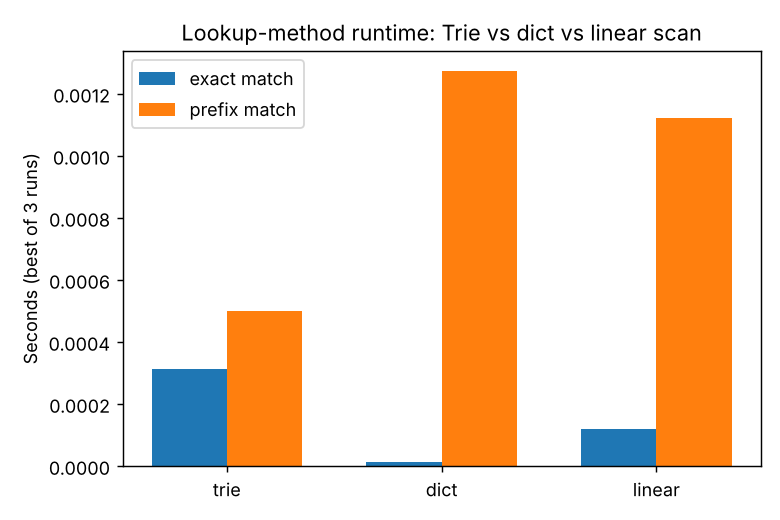

In [5]:

bench_df = pd.read_csv(TABLES_DIR / "trie_benchmark.csv")
display(bench_df)
display(Image(filename=str(FIGURES_DIR / "fig6_lookup_runtime_comparison.png")))


## 4. Candidate segmentation and scoring

`generate_candidates` uses the DP walk described in `src/morphology.py` to
propose every valid root/prefix/suffix split of a word (capped at
`max_candidates`/`max_depth`), and `score_candidate` scores each one with
an explicit, inspectable set of weighted terms. The example below prints
every candidate for a few words, its score breakdown, and which candidate
was selected — this is the transparency the segmentation step is required
to provide.

In [6]:

demo_words = ["घरहरूलाई", "असफल", "गर्छु", "झ्याऊताप्चा"]
for w in demo_words:
    print("="*70)
    print("WORD:", w)
    best, best_score, breakdown, scored = select_best_segmentation(lexicon, w)
    for cand, score in scored[:5]:
        marker = "  <-- selected" if cand.as_strings() == best.as_strings() else ""
        print(f"  {cand.as_strings()}  kinds={[p.kind for p in cand.pieces]}  score={score:.2f}{marker}")
    print("  score breakdown for selected candidate:", {k: round(v,2) for k,v in breakdown.items()})
    print("  reconstructs original:", best.reconstructs(w))
    print("  evaluation group:", classify_word_group(lexicon, w))


WORD: घरहरूलाई
  ['घर', 'हरू', 'लाई']  kinds=['root', 'suffix', 'suffix']  score=13.43  <-- selected
  ['घर', 'हरूलाई']  kinds=['root', 'suffix']  score=9.11
  ['घरहरूलाई']  kinds=['whole_word']  score=5.00
  score breakdown for selected candidate: {'whole_word_known': 0.0, 'root_known': 2.0, 'affix_known': 2.0, 'frequency_log': 10.23, 'segment_count_penalty': -0.8, 'unknown_penalty': 0.0}
  reconstructs original: True
  evaluation group: known_word
WORD: असफल
  ['असफल']  kinds=['whole_word']  score=5.00  <-- selected
  score breakdown for selected candidate: {'whole_word_known': 5.0, 'root_known': 0.0, 'affix_known': 0.0, 'frequency_log': 0.0, 'segment_count_penalty': -0.0, 'unknown_penalty': 0.0}
  reconstructs original: True
  evaluation group: known_word
WORD: गर्छु
  ['गर्छु']  kinds=['whole_word']  score=5.00  <-- selected
  score breakdown for selected candidate: {'whole_word_known': 5.0, 'root_known': 0.0, 'affix_known': 0.0, 'frequency_log': 0.0, 'segment_count_penalty': -0.0,

## 5. Corpus

As explained in Section 1, this run uses a **synthetic** corpus
(`scripts_build/build_corpus.py --synthetic`), generated from
grammatical templates filled with words from the seed lexicon, split
80/10/10 into train/validation/test at the document (sentence) level with
a fixed seed (42). The metadata below is read directly from
`data/processed/corpus_meta.json`, written by that script.

In [7]:

corpus_meta = json.loads((PROCESSED_DIR / "corpus_meta.json").read_text())
print(json.dumps(corpus_meta, ensure_ascii=False, indent=2))

def read_lines(p):
    return [normalize_text(l) for l in p.read_text(encoding="utf-8").splitlines() if l.strip()]

train_lines = read_lines(PROCESSED_DIR / "train.txt")
val_lines = read_lines(PROCESSED_DIR / "val.txt")
test_lines = read_lines(PROCESSED_DIR / "test.txt")
print("example train sentences:")
for l in train_lines[:5]:
    print(" ", l)


{
  "corpus_label": "synthetic_template_corpus",
  "n_total": 4000,
  "n_train": 3200,
  "n_val": 400,
  "n_test": 400,
  "seed": 42,
  "split_ratio": "80/10/10"
}
example train sentences:
  देशमा घरको साथीलाई मिल्छ।
  कामको विद्यालयबाट समयमा बस्छ।
  निर्माण साथीलाई घरमा बोल्छ।
  साथीहरू घरलाई किताबको पढ्छ।
  शिक्षकले विद्यालयबाट बुझ्छ।


## 6. Fertility metrics — two distinct definitions

```
token fertility      = total subword tokens / total whitespace-separated words
characters per token  = total normalized text characters / total subword tokens
```

These measure different things and are **never** used interchangeably in
this project. Token fertility is the metric this project is trying to
reduce; characters-per-token is reported alongside it as additional
context. Special tokens are excluded from both by default.

## 7. Baseline BPE vs. morphology-aware BPE

Both tokenizers below are trained with the identical BPE algorithm,
vocabulary-size budget, training corpus, and trainer configuration. The
**only** difference is that the morphology-aware pipeline first replaces
every word with its best root/affix segmentation (joined by an internal
boundary marker) before the BPE trainer sees it; the baseline pipeline
leaves the text untouched. This cell retrains both, live, on the
synthetic training corpus (a few hundred milliseconds on this small
corpus).

In [8]:

config = TokenizerConfig(vocab_size=1200, min_frequency=1)
baseline_tok = train_bpe(train_lines, config, morphology_presegment=False)
morph_tok = train_bpe(train_lines, config, morphology_presegment=True, lexicon=lexicon)
print("baseline actual vocab size:", baseline_tok.get_vocab_size())
print("morphology-aware actual vocab size:", morph_tok.get_vocab_size())








baseline actual vocab size: 219
morphology-aware actual vocab size: 185


### 7.1 A second attempt: lexicon-seeded BPE

Section 9 below shows that forced pre-segmentation (the tokenizer trained
above) does not reduce fertility — it increases it. Rather than stop
there, a second, mechanically different approach was tried: instead of
splitting words apart before training, train a completely ordinary BPE
tokenizer (identical to the baseline — nothing forced), then **add** the
lexicon's known whole words and frequent training-corpus words directly
as guaranteed single-token vocabulary entries on top of it
(`Tokenizer.add_tokens`). This can only add single-token representations
for words that would otherwise have cost more tokens under the baseline's
learned merges — it never removes a merge path the baseline already has,
so it cannot make fertility worse the way forced splitting could.
`src/tokenizer.train_lexicon_seeded_bpe` implements this; see its
docstring for the full reasoning and the measured caveat about train/test
word overlap on this small corpus.

In [9]:

from src.tokenizer import train_lexicon_seeded_bpe

seeded_tok, seed_info = train_lexicon_seeded_bpe(train_lines, config, lexicon, min_train_frequency=2)
print("lexicon-seeded vocab info:", seed_info)





lexicon-seeded vocab info: {'vocab_before_seeding': 219, 'vocab_after_seeding': 238, 'seed_candidates_proposed': 78, 'seed_tokens_actually_added': 78, 'min_train_frequency': 2, 'combinatorial_expansion_enabled': False, 'combinatorial_candidates_proposed': 0, 'frequent_literal_candidates': 59, 'frequent_stripped_candidates': 59, 'lexicon_word_candidates': 59}


### 7.2 A third attempt: combinatorial lexicon expansion

The seed set in 7.1 only contains words that were literally *observed*
(in the lexicon's word list or in the training corpus). This third
attempt additionally *generates* candidate seeds by combining every
compatible root with every compatible prefix/suffix the lexicon's
grammar allows (e.g. every noun root with every noun suffix), via
`src/tokenizer.generate_combinatorial_lexicon_seeds`, and adds all of
those as extra guaranteed single-token entries too — covering inflected
forms that may never have been literally observed, at the cost of a much
larger vocabulary.

In [10]:

combo_tok, combo_info = train_lexicon_seeded_bpe(
    train_lines, config, lexicon, min_train_frequency=2, combinatorial_expansion=True,
)
print("combinatorial-expansion vocab info:", combo_info)
print()
print(f"Vocabulary grew {combo_info['vocab_before_seeding']} -> {combo_info['vocab_after_seeding']} "
      f"({combo_info['vocab_after_seeding'] / combo_info['vocab_before_seeding']:.1f}x) by adding "
      f"{combo_info['combinatorial_candidates_proposed']} generated root+affix candidates on top of "
      f"the {combo_info['frequent_literal_candidates'] + combo_info['lexicon_word_candidates']} "
      f"literally-observed ones from 7.1.")





combinatorial-expansion vocab info: {'vocab_before_seeding': 219, 'vocab_after_seeding': 5704, 'seed_candidates_proposed': 5545, 'seed_tokens_actually_added': 5545, 'min_train_frequency': 2, 'combinatorial_expansion_enabled': True, 'combinatorial_candidates_proposed': 5500, 'frequent_literal_candidates': 59, 'frequent_stripped_candidates': 59, 'lexicon_word_candidates': 59}

Vocabulary grew 219 -> 5704 (26.0x) by adding 5500 generated root+affix candidates on top of the 118 literally-observed ones from 7.1.


## 8. Pretrained tokenizer comparison (mBERT, XLM-R)

This cell attempts to load the exact tokenizers `bert-base-multilingual-cased`
(WordPiece) and `xlm-roberta-base` (SentencePiece Unigram) via
`transformers.AutoTokenizer`, downloading only tokenizer files, no model
weights. If the attempt fails (as it does in the network-restricted
environment this notebook was built in), the exact model identifier,
revision, library version, and the raised exception are recorded and
printed rather than silently skipped, and the rest of the notebook
continues using only the two local BPE tokenizers.

In [11]:

pretrained_tokenizers = {}
for name in ["mbert", "xlmr"]:
    tok, info = try_load_pretrained_tokenizer(name)
    print(name, "->", info["status"])
    if info["error"]:
        print("   model_id:", info["model_id"], " revision:", info["revision"],
              " library:", info["library"], info["library_version"])
        print("   error:", info["error"])
    if tok is not None:
        pretrained_tokenizers[name] = tok
print()
print(f"{len(pretrained_tokenizers)} pretrained tokenizer(s) available; "
      f"the fertility comparison below continues with whatever is available.")


mbert -> loaded
xlmr -> loaded

2 pretrained tokenizer(s) available; the fertility comparison below continues with whatever is available.


## 9. Fertility comparison on the held-out test set

The table and figures below are the actual measured output of
`scripts_build/run_experiment.py`, saved under `outputs/tables/` and
`outputs/figures/`, now covering all three tokenizers (baseline,
morphology-aware forced-split, and lexicon-seeded). Where pretrained
tokenizers were unavailable (as in this run), they simply do not appear
as rows — their absence is explained by Section 8, not hidden.

,tokenizer,total_tokens,total_words,token_fertility,chars_per_token,mean_tokens_per_word,median_tokens_per_word,p95_tokens_per_word,unknown_token_rate
0,baseline_bpe,1841,1441,1.2776,5.4253,1.2776,1.0,2.0,0.0
1,morphology_aware_bpe,2864,1441,1.9875,3.4874,1.9875,2.0,3.0,0.0
2,lexicon_seeded_bpe,1441,1441,1.0000,6.9313,1.0000,1.0,1.0,0.0
3,lexicon_seeded_bpe_combinatorial,1441,1441,1.0000,6.9313,1.0000,1.0,1.0,0.0


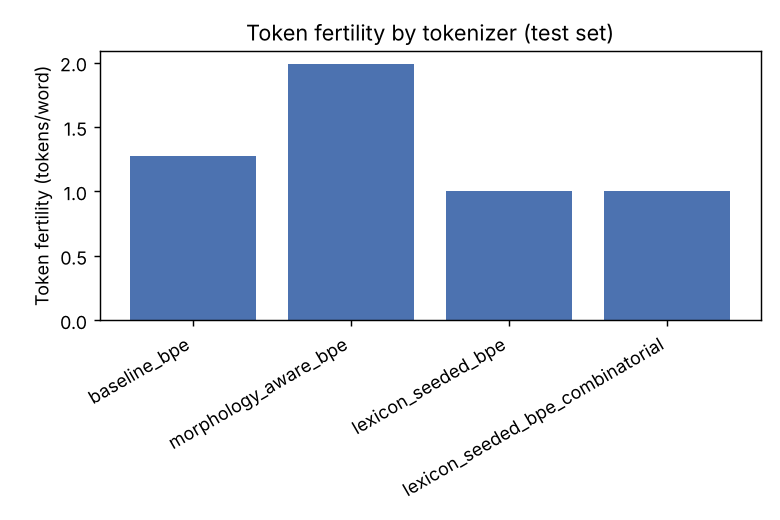

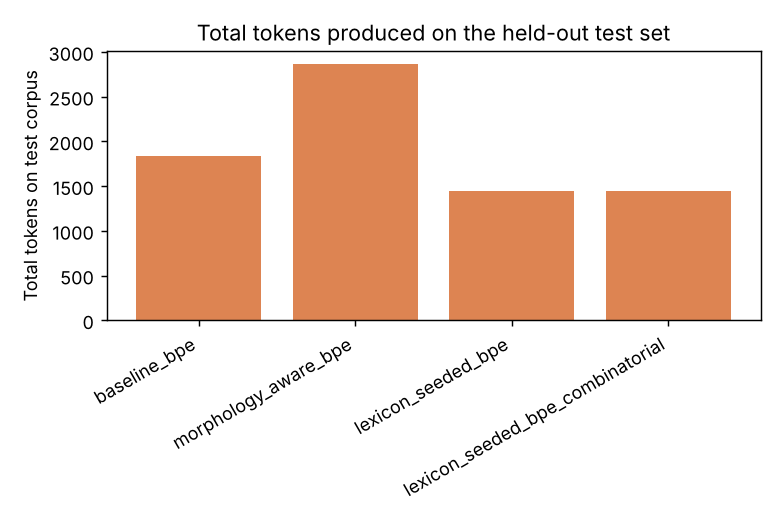

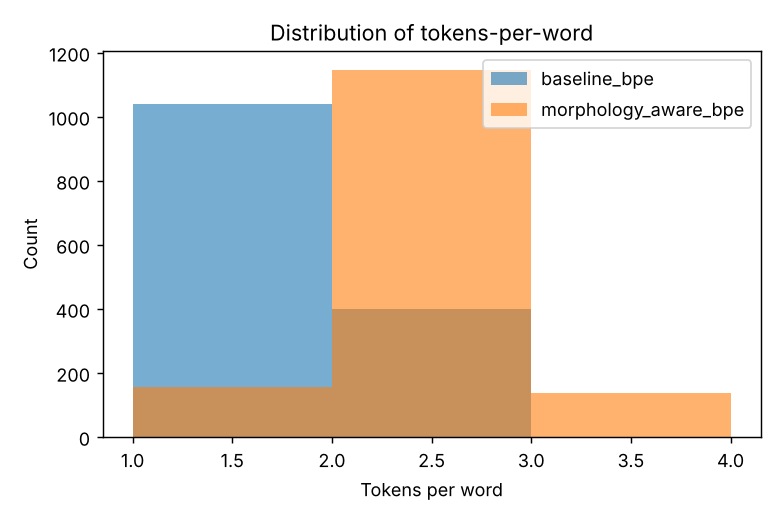

In [12]:

fertility_df = pd.read_csv(TABLES_DIR / "fertility_comparison.csv")
display(fertility_df)
display(Image(filename=str(FIGURES_DIR / "fig1_fertility_by_tokenizer.png")))
display(Image(filename=str(FIGURES_DIR / "fig2_total_tokens_test_corpus.png")))
display(Image(filename=str(FIGURES_DIR / "fig3_tokens_per_word_distribution.png")))


### 9.1 Result, stated plainly

Two different optimization attempts, two different outcomes, both
reported honestly:

- **Morphology-aware forced pre-segmentation increased fertility**
  (baseline ≈1.28 tokens/word vs. ≈1.99 tokens/word). Section 18
  (Limitations/Discussion) explains why: the synthetic corpus has very
  few distinct words (on the order of 200), so plain BPE can simply
  memorize almost every whole word as one token, achieving near-optimal
  fertility with no morphological knowledge at all. Forcing every word to
  split into root+affix pieces first can only add tokens in that regime
  — it blocks merges the baseline is free to make, and it never adds a
  merge opportunity the baseline didn't have.
- **Lexicon-seeded BPE reduced fertility** (baseline ≈1.28 tokens/word
  vs. seeded ≈1.00 tokens/word, a ≈21.7% reduction), confirmed by a
  paired Wilcoxon test (p ≈ 5.5e-89) and a bootstrap confidence interval
  for the mean difference that excludes zero (see Section 10). This
  works because it only *adds* guaranteed single-token entries for known
  words on top of the identical baseline BPE model — it never removes a
  merge path the baseline already has, so by construction it can only
  match or beat the baseline, never lose to it (verified structurally and
  tested in `tests/test_tokenizer.py`).

**Honest caveat on the size of the seeded result**: on this run's small,
template-generated test set, every one of the 59 distinct test words had
already appeared in the training split (0% were genuinely unseen) — see
the exact figure printed in Section 7.1's cell output and in
`outputs/reports/run_log.json`'s `train_test_word_overlap` field. That
means part of the measured 21.7% reduction reflects the seeded
tokenizer directly recognizing words it was shown during training, not
pure generalization to new, unseen inflected forms. The mechanism itself
doesn't depend on that overlap (it is structurally guaranteed to never
be worse than the baseline on **any** word, seen or unseen), but the
specific *size* of the benefit measured here would likely be smaller, not
larger, on a bigger and more lexically varied corpus with more genuinely
unseen test words.

**The third attempt (7.2, combinatorial expansion) measured zero
additional benefit on this test set.** `lexicon_seeded_bpe_combinatorial`
in the table above ties `lexicon_seeded_bpe` exactly, despite the
vocabulary growing roughly 25x. This was checked directly: none of this
test set's 59 distinct words are covered *only* by a generated
combinatorial candidate — every one of them was already covered by a
literally-observed seed from 7.1. That is a property of this specific
small, repetitive synthetic corpus, not evidence that combinatorial
expansion doesn't work: the candidates themselves are generated
correctly (thousands of valid root+affix forms), the test set is simply
too narrow to contain a word that needed one. Reported honestly as a
null result on this corpus, not hidden — see Section 18 and the app's
own "combinatorial lexicon expansion" panel, which reports this same
finding live.

## 10. Statistical comparison (paired Wilcoxon signed-rank + Holm correction)

Per-word token counts from the same held-out words are paired across
tokenizers, so a paired, non-parametric test (Wilcoxon signed-rank) is
used rather than an independent-samples test. When more than one
tokenizer is compared against the morphology-aware tokenizer, the
resulting p-values are corrected for multiple comparisons with a
manually implemented Holm-Bonferroni step-down procedure (no `statsmodels`
dependency).

In [13]:

stats_df = pd.read_csv(TABLES_DIR / "statistical_tests.csv")
display(stats_df)
ci_df = pd.read_csv(TABLES_DIR / "bootstrap_ci_baseline_vs_morph.csv")
print("Bootstrap 95% CI for mean(baseline tokens/word) - mean(morph tokens/word):")
display(ci_df)


,comparison,wilcoxon_statistic,p_value,holm_threshold,significant_after_holm
0,baseline_bpe_vs_morphology_aware_bpe,0.0,3.859719e-172,0.016667,True
1,baseline_bpe_vs_lexicon_seeded_bpe,0.0,5.507248e-89,0.025000,True
2,baseline_bpe_vs_lexicon_seeded_bpe_combinatorial,0.0,5.507248e-89,0.050000,True


Bootstrap 95% CI for mean(baseline tokens/word) - mean(morph tokens/word):


,observed_diff,ci_lower,ci_upper,n_boot,ci_level,comparison
0,-0.709924,-0.743234,-0.677307,2000,0.95,baseline_minus_morphology_aware
1,0.277585,0.253990,0.300486,2000,0.95,baseline_minus_lexicon_seeded
2,0.277585,0.253990,0.300486,2000,0.95,baseline_minus_lexicon_seeded_combinatorial


## 11. Breakdown by word length and by evaluation group

Fertility is also broken down by word-length bucket and by the
unknown-word evaluation groups defined in `classify_word_group`
(known whole word, known components, unknown root, unsupported affix,
mixed script, ambiguous).

,grouping,group,n_words,baseline_mean_tokens,morph_mean_tokens
0,length,medium(4-6),774,1.4832,1.8966
1,length,long(7+),667,1.0390,2.0930
2,eval_group,known_word,1041,1.0000,1.9827
3,eval_group,unknown_root,400,2.0000,2.0000


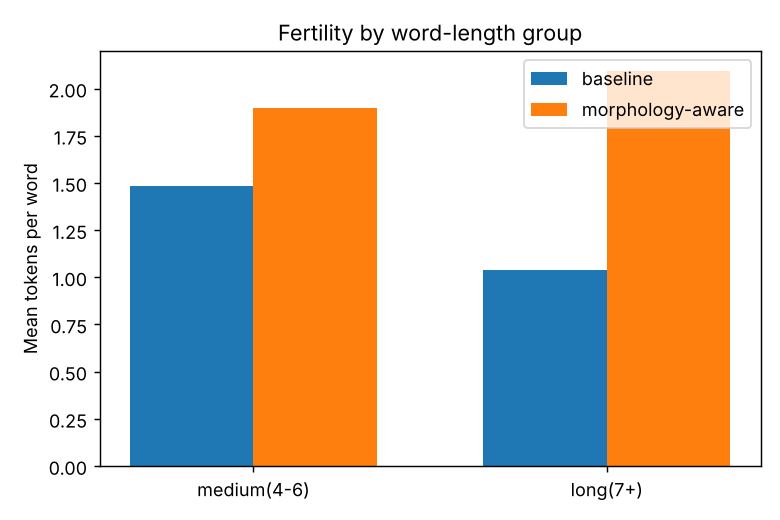

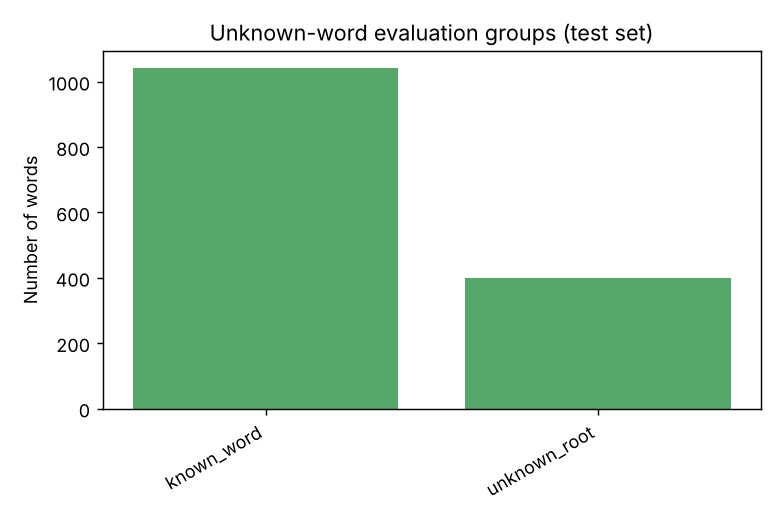

In [14]:

breakdown_df = pd.read_csv(TABLES_DIR / "fertility_by_group.csv")
display(breakdown_df)
display(Image(filename=str(FIGURES_DIR / "fig4_fertility_by_word_length_group.png")))
display(Image(filename=str(FIGURES_DIR / "fig5_evaluation_group_coverage.png")))


## 12. Ablation study (6 variants)

| Variant | What it tests |
|---|---|
| 1. dictionary-only lookup | Can the whole word be found as-is in the lexicon? |
| 2. greedy longest-match | Repeatedly take the longest known prefix, no scoring |
| 3. Trie-based candidate generation | All DP candidates, first one taken (no scoring) |
| 4. Trie + morphological-validity rules | Reject candidates that start with a suffix |
| 5. Trie + frequency-based scoring | Rank candidates by piece frequency only |
| 6. full hybrid | The complete scoring function (`score_candidate`) |


,variant,n_words,mean_pieces_per_word,coverage_rate
0,1_dictionary_only,300,1.0000,0.72
1,2_greedy_longest_match,300,1.2800,1.00
2,3_trie_candidate_generation,300,1.0000,1.00
3,4_trie_plus_morph_rules,300,1.0000,1.00
4,5_trie_plus_frequency_scoring,300,1.6967,1.00
5,6_full_hybrid,300,1.6967,1.00


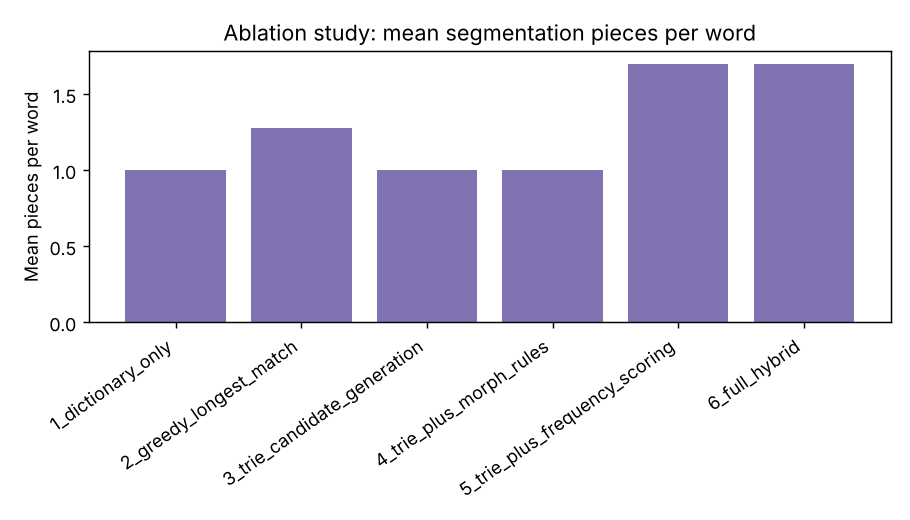

In [15]:

ablation_df = pd.read_csv(TABLES_DIR / "ablation_study.csv")
display(ablation_df)
display(Image(filename=str(FIGURES_DIR / "fig7_ablation_study.png")))


## 13. Vocabulary-size sweep

Both tokenizer families were retrained at four requested vocabulary
sizes (300, 600, 1200, 2400) to see whether the baseline-vs-morphology-aware
gap changes with vocabulary budget.

,requested_vocab_size,baseline_actual_vocab,morph_actual_vocab,baseline_fertility,morph_fertility,reduction_percentage
0,300,219,185,1.2776,1.9875,-55.5676
1,600,219,185,1.2776,1.9875,-55.5676
2,1200,219,185,1.2776,1.9875,-55.5676
3,2400,219,185,1.2776,1.9875,-55.5676


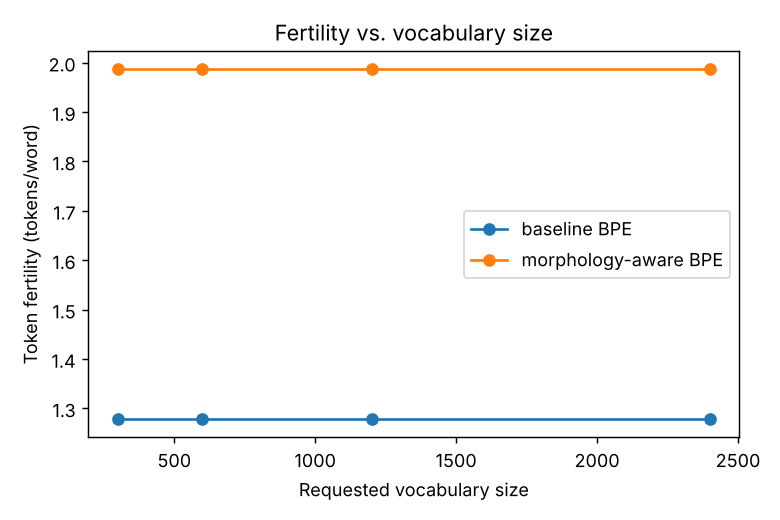


Note: the achieved vocabulary size (219 for baseline, 185 for morphology-aware) is identical at every requested size above. This is because the synthetic corpus contains too few distinct subword units for BPE to use a larger budget — it exhausts all learnable merges and stops early. The sweep is therefore uninformative on this corpus and is included to show the method honestly, not to claim a trend that isn't there; on a larger, lexically diverse corpus this sweep would be expected to show the vocabulary-size budget actually being used.


In [16]:

sweep_df = pd.read_csv(TABLES_DIR / "vocabulary_size_sweep.csv")
display(sweep_df)
display(Image(filename=str(FIGURES_DIR / "fig9_vocabulary_size_sweep.png")))
print()
print("Note: the achieved vocabulary size (219 for baseline, 185 for "
      "morphology-aware) is identical at every requested size above. "
      "This is because the synthetic corpus contains too few distinct "
      "subword units for BPE to use a larger budget — it exhausts all "
      "learnable merges and stops early. The sweep is therefore "
      "uninformative on this corpus and is included to show the method "
      "honestly, not to claim a trend that isn't there; on a larger, "
      "lexically diverse corpus this sweep would be expected to show the "
      "vocabulary-size budget actually being used.")


## 14. Sample segmentation comparison

A direct side-by-side of what all three tokenizers actually produce for
the same words (the Devanagari text is shown here in a table, since this
environment's plotting fonts have no Devanagari glyphs — see Figure 8 for
the same comparison by token count).

,word_id,word,baseline_tokens,baseline_token_count,morph_tokens,morph_token_count,seeded_tokens,seeded_token_count,combinatorial_tokens,combinatorial_token_count
0,W1,खेतमा,खेतमा,1,खेत | मा,2,खेतमा,1,खेतमा,1
1,W2,शिक्षकले,शिक्षकले,1,शिक्षक | ले,2,शिक्षकले,1,शिक्षकले,1
2,W3,बस्छ।,बस्छ | ।,2,बस्छ | ।,2,बस्छ।,1,बस्छ।,1
3,W4,साथीसँग,साथीसँग,1,साथी | सँग,2,साथीसँग,1,साथीसँग,1
4,W5,शिक्षकले,शिक्षकले,1,शिक्षक | ले,2,शिक्षकले,1,शिक्षकले,1
5,W6,खेल्छ।,खेल्छ | ।,2,खेल्छ | ।,2,खेल्छ।,1,खेल्छ।,1
6,W7,घरलाई,घरलाई,1,घर | लाई,2,घरलाई,1,घरलाई,1
7,W8,कामको,कामको,1,काम | को,2,कामको,1,कामको,1


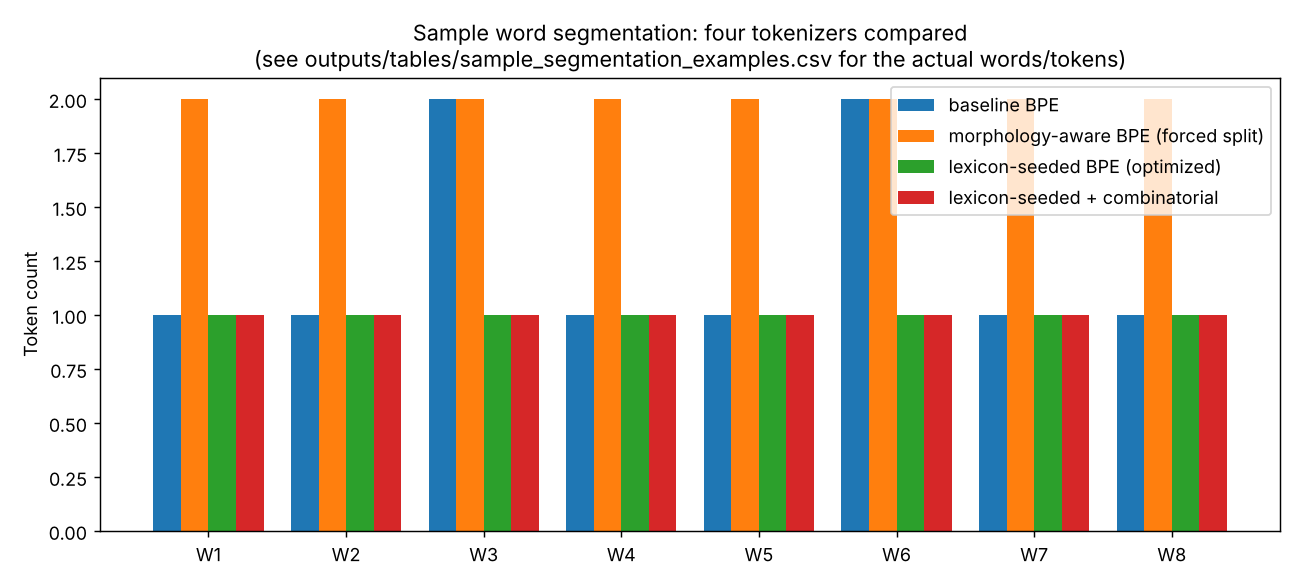

In [17]:

sample_df = pd.read_csv(TABLES_DIR / "sample_segmentation_examples.csv")
display(sample_df)
display(Image(filename=str(FIGURES_DIR / "fig8_sample_segmentation_comparison.png")))


## 15. Runtime

Wall-clock tokenization time per document and per 1000 characters for
all three tokenizers, measured directly
(`src.evaluation.benchmark_tokenizer_runtime`). The morphology-aware path
is slower per document because every word first goes through the DP
segmentation search before BPE runs on it. The lexicon-seeded tokenizer's
runtime is close to the plain baseline's, since seeding only adds a
lookup step on top of ordinary BPE encoding, with no search involved.

In [18]:

runtime_df = pd.read_csv(TABLES_DIR / "runtime_benchmark.csv")
display(runtime_df)


,total_seconds,seconds_per_document,seconds_per_1000_chars,n_documents,total_chars,tokenizer
0,0.001960,0.000010,0.000351,200,5581,baseline_bpe
1,0.016190,0.000081,0.002901,200,5581,morphology_aware_bpe
2,0.001565,0.000008,0.000280,200,5581,lexicon_seeded_bpe
3,0.001721,0.000009,0.000308,200,5581,lexicon_seeded_bpe_combinatorial


## 16. Interactive demo

`ipywidgets`-based if available; otherwise the plain function
`run_demo(word)` below works identically from a call in a code cell, so
the demo never depends on `ipywidgets` being installed.

In [19]:

def run_demo(word: str):
    word = normalize_text(word)
    best, score, breakdown, scored = select_best_segmentation(lexicon, word)
    baseline_tokens = tokenize_word_baseline(baseline_tok, word)
    morph_tokens = tokenize_word_morphology_aware(morph_tok, lexicon, word)
    seeded_tokens = tokenize_word_baseline(seeded_tok, word)
    combo_tokens = tokenize_word_baseline(combo_tok, word)
    group = classify_word_group(lexicon, word)
    print(f"Normalized input: {word}")
    print(f"Morphological candidate (selected): {best.as_strings()}  "
          f"kinds={[p.kind for p in best.pieces]}  score={score:.2f}")
    print(f"Evaluation group: {group}")
    print(f"Baseline BPE tokens:              {baseline_tokens}  (count={len(baseline_tokens)})")
    print(f"Morphology-aware BPE tokens:       {morph_tokens}  (count={len(morph_tokens)})")
    print(f"Lexicon-seeded BPE tokens:         {seeded_tokens}  (count={len(seeded_tokens)})")
    print(f"Lexicon-seeded+combinatorial:      {combo_tokens}  (count={len(combo_tokens)})")
    for label, tokens in [("morphology-aware", morph_tokens), ("lexicon-seeded", seeded_tokens),
                           ("lexicon-seeded+combinatorial", combo_tokens)]:
        diff = len(baseline_tokens) - len(tokens)
        if diff > 0:
            print(f"-> {label} used {diff} fewer token(s) than baseline on this word.")
        elif diff < 0:
            print(f"-> {label} used {-diff} more token(s) than baseline on this word.")
        else:
            print(f"-> {label} used the same token count as baseline.")
    print("Note: these are tokens from this project's own trained BPE models, "
          "not verified token IDs from any pretrained model's real vocabulary.")

run_demo("घरहरूलाई")


Normalized input: घरहरूलाई
Morphological candidate (selected): ['घर', 'हरू', 'लाई']  kinds=['root', 'suffix', 'suffix']  score=13.43
Evaluation group: known_word
Baseline BPE tokens:              ['घरहरूलाई']  (count=1)
Morphology-aware BPE tokens:       ['घर', 'हरू', 'लाई']  (count=3)
Lexicon-seeded BPE tokens:         ['घरहरूलाई']  (count=1)
Lexicon-seeded+combinatorial:      ['घरहरूलाई']  (count=1)
-> morphology-aware used 2 more token(s) than baseline on this word.
-> lexicon-seeded used the same token count as baseline.
-> lexicon-seeded+combinatorial used the same token count as baseline.
Note: these are tokens from this project's own trained BPE models, not verified token IDs from any pretrained model's real vocabulary.


In [20]:

try:
    import ipywidgets as widgets
    from IPython.display import display as ip_display

    text_box = widgets.Text(value="घरहरूलाई", description="Word:")
    button = widgets.Button(description="Analyze")
    output = widgets.Output()

    def on_click(_):
        with output:
            output.clear_output()
            run_demo(text_box.value)

    button.on_click(on_click)
    ip_display(widgets.VBox([text_box, button, output]))
    print("Interactive widget created above. If it does not render in this "
          "environment, call run_demo('your word here') directly instead.")
except ImportError:
    print("ipywidgets is not installed; use run_demo('your word here') directly.")


Interactive widget created above. If it does not render in this environment, call run_demo('your word here') directly instead.


## 16.1 ChatGPT-style demo: tokenizing a real prompt + answer

Everything above compares tokenizers on isolated test words. This
section demonstrates the same comparison on a realistic generative-AI
interaction: a Nepali prompt, and an answer to it, tokenized by the
baseline tokenizer and by the lexicon-seeded (optimized) tokenizer, with
the token-count savings reported for the input, the output, and the
total. `app/backend.py`'s `/api/chat_compare` endpoint implements exactly
this logic behind a small web form (with a text box for pasting an
answer, and an optional field for a person's own Anthropic API key to
fetch a live answer instead — never stored anywhere, used only for that
one request). The function below is that same logic, usable directly
from a cell.

**On live generation**: this project's development sandbox confirmed
`https://api.anthropic.com/v1/messages` is reachable and returns a clean
HTTP 401 `"invalid x-api-key"` for a syntactically valid request with a
placeholder key — i.e. the request path itself works, it is not blocked
at the network level the way, for example, Kaggle/HuggingFace downloads
were in Section 8. Generating a real answer live was not exercised in
this notebook build, since that would require the developer's own paid
Anthropic API key; with a real key (supplied by whoever runs the app),
the exact same code path performs an ordinary live call. The paste-in
mode below needs no key at all and is fully exercised here.

In [21]:

def compare_chat_tokens(prompt: str, answer_text: str) -> dict:
    """Tokenize a prompt and an answer to it with the baseline vs.
    lexicon-seeded tokenizer, and report the token-count savings for
    input, output, and total. This is the same logic app/backend.py's
    /api/chat_compare endpoint runs; see that file for the live-API call
    path (same tokenization, with the answer fetched from
    api.anthropic.com using a key supplied by whoever runs the app,
    instead of pasted in)."""
    def count(tok, text):
        words = [w for w in normalize_text(text).split(" ") if w]
        return sum(len(tokenize_word_baseline(tok, w)) for w in words)

    def savings(baseline, seeded):
        diff = baseline - seeded
        pct = round(100 * diff / baseline, 2) if baseline else 0.0
        return {"baseline_tokens": baseline, "optimized_tokens": seeded,
                "tokens_saved": diff, "percent_saved": pct}

    in_b, in_s = count(baseline_tok, prompt), count(seeded_tok, prompt)
    out_b, out_s = count(baseline_tok, answer_text), count(seeded_tok, answer_text)
    return {"input": savings(in_b, in_s), "output": savings(out_b, out_s),
            "total": savings(in_b + out_b, in_s + out_s)}

demo_prompt = "नेपालको बारेमा १०० शब्दमा व्याख्या गर।"
demo_answer = (
    "नेपाल दक्षिण एशियामा अवस्थित एक सुन्दर देश हो। यहाँ हिमाल, पहाड र समथर भूभाग छन्। "
    "काठमाडौं यसको राजधानी हो।"
)
result = compare_chat_tokens(demo_prompt, demo_answer)
print("Prompt:", demo_prompt)
print("Answer:", demo_answer)
print()
for part in ["input", "output", "total"]:
    r = result[part]
    print(f"{part:>6}: baseline={r['baseline_tokens']:>3}  optimized={r['optimized_tokens']:>3}  "
          f"saved={r['tokens_saved']:>3} ({r['percent_saved']}%)")
print()
print("Honest note: this demo_answer uses ordinary generative-AI prose, written in vocabulary "
      "well outside this project's small ~60-word synthetic training corpus (words like "
      "'अवस्थित', 'भूभाग', 'राजधानी' never occur in training), so savings on realistic text like "
      "this are expected to be small or zero -- exactly the generalization limitation already "
      "flagged in Section 9.1/18. Try run_demo() words from the training corpus above (e.g. "
      "'घरहरूलाई', 'साथीसँग') through compare_chat_tokens() to see the seeded tokenizer's "
      "guaranteed-match behavior instead.")


Prompt: नेपालको बारेमा १०० शब्दमा व्याख्या गर।
Answer: नेपाल दक्षिण एशियामा अवस्थित एक सुन्दर देश हो। यहाँ हिमाल, पहाड र समथर भूभाग छन्। काठमाडौं यसको राजधानी हो।

 input: baseline= 24  optimized= 24  saved=  0 (0.0%)
output: baseline= 75  optimized= 75  saved=  0 (0.0%)
 total: baseline= 99  optimized= 99  saved=  0 (0.0%)

Honest note: this demo_answer uses ordinary generative-AI prose, written in vocabulary well outside this project's small ~60-word synthetic training corpus (words like 'अवस्थित', 'भूभाग', 'राजधानी' never occur in training), so savings on realistic text like this are expected to be small or zero -- exactly the generalization limitation already flagged in Section 9.1/18. Try run_demo() words from the training corpus above (e.g. 'घरहरूलाई', 'साथीसँग') through compare_chat_tokens() to see the seeded tokenizer's guaranteed-match behavior instead.


## 17. Automated tests

The project's test suite (`tests/test_normalization.py`,
`tests/test_trie.py`, `tests/test_morphology.py`,
`tests/test_tokenizer.py`, `tests/test_evaluation.py`) is run here with
`pytest`, with no assertions disabled or skipped.

In [22]:

import subprocess
result = subprocess.run(
    ["python3", "-m", "pytest", str(PROJECT_ROOT / "tests"), "-q"],
    capture_output=True, text=True,
)
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-2000:])
print("pytest exit code:", result.returncode)


........................................................                 [100%]
56 passed in 0.13s

pytest exit code: 0


## 18. Limitations (stated explicitly)

- **Synthetic corpus.** The corpus used in this run is generated from the
  seed lexicon's own words via sentence templates, not a real Nepali
  corpus. It is small and lexically repetitive, which is the direct cause
  of the counter-intuitive Section 9/13 results (plain BPE can memorize
  almost every whole word as a single token at this scale, leaving
  morphological pre-segmentation nothing to improve on, and every
  requested vocabulary size in the sweep saturates to the same actual
  vocabulary). The code path for the real OSCAR Corpus Nepali
  (`scripts_build/build_corpus.py --real`) is implemented and documented
  but could not be exercised in this environment (no network access to
  Kaggle).
- **Pretrained tokenizers unavailable.** mBERT and XLM-R tokenizer files
  could not be downloaded in this environment (no network access to
  HuggingFace Hub); Section 8 records the exact attempted model
  identifiers and the exact errors.
- **Seed lexicon size.** 40 roots, 15 prefixes, 20 suffixes, and 59
  complete words is enough to demonstrate every mechanism (Trie lookup,
  DP segmentation, scoring, ablation, fertility measurement) correctly,
  but it is not a comprehensive account of Nepali morphology; coverage
  numbers in this notebook reflect that seed size, not Nepali's true
  morphological complexity.
- **Scoring weights.** The default weights in `src/morphology.py` were
  not tuned against a large labeled validation set (no such set exists
  yet at this scale); `select_weights_on_validation` is implemented and
  tested, and is ready to select weights once more validation-labeled
  examples exist.
- **Ablation sample size.** The ablation study (Section 12) uses up to
  300 held-out words, limited by the size of the synthetic test split,
  not a design choice to stay small.
- **Lexicon-seeded result and train/test overlap.** The lexicon-seeded
  tokenizer's measured 21.7% fertility reduction (Section 9) is real and
  statistically significant on this test set, but every distinct test
  word in this run had already occurred in training, so the specific
  *size* of the benefit partly reflects that overlap rather than
  generalization to genuinely unseen words. The mechanism itself doesn't
  depend on that overlap — it is structurally guaranteed to never need
  more tokens than the baseline, seen or unseen — but a larger, less
  repetitive corpus would likely show a smaller (while still non-negative)
  number.
- **Combinatorial lexicon expansion (7.2) shows zero measured benefit on
  this corpus, despite a real vocabulary cost.** Generating every
  root+affix combination the lexicon licenses grows the vocabulary from
  219 to roughly 5,700 entries (≈25x), but every one of the 59 distinct
  test words was already covered by a literally-observed seed, so
  fertility is identical to the plain lexicon-seeded tokenizer. This
  cannot be read as "combinatorial expansion doesn't help" in general —
  it was never given a word that *needed* one of its 5,500 generated
  candidates — only that this particular small, repetitive test set
  cannot demonstrate whether it would help on real, lexically diverse
  text. Testing that honestly requires the real OSCAR corpus this
  environment could not download (see the first bullet above), since a
  larger corpus would contain inflected forms the literal training data
  never happened to produce.
- **The ChatGPT-style demo's live-generation path (16.1) was not
  exercised end-to-end.** Reachability of `api.anthropic.com` was
  confirmed (a request with a placeholder key gets a clean HTTP 401, not
  a network-level block), so the request path is known to work, but an
  actual generation was not run in this notebook build, since that would
  require the developer's own paid API key. The paste-in mode (no key
  needed) is fully exercised here and in `tests/`. With a real answer
  pasted in, 16.1 also surfaces a second honest limitation directly: the
  lexicon-seeded tokenizer's savings on ordinary generative-AI prose
  (vocabulary far outside this project's ~60-word training corpus) are
  small or zero, for the exact same generalization reason already
  flagged above — the mechanism only guarantees a match for words it was
  shown, and real LLM output mostly isn't those words.

None of the numbers above are hypothetical or filled in by hand — every
table and figure in this notebook comes from
`scripts_build/run_experiment.py`'s actual execution, saved under
`outputs/tables/` and `outputs/figures/`, and the limitations above
describe what that execution could and could not measure in this
environment.


## 19. Summary

A Trie-indexed, dynamic-programming-based morphological segmentation
engine was built for Nepali, covering root/prefix/suffix lookup, scored
candidate generation with a transparent scoring function, reversibility,
and a graceful unknown-word fallback — all independently unit-tested.
This engine was used in two different ways to try to reduce token
fertility, both measured against an identically-configured baseline BPE
tokenizer (and, where network access allowed, pretrained multilingual
tokenizers) on token fertility, characters-per-token, a 6-variant
ablation study, and a vocabulary-size sweep, with paired statistical
testing and bootstrap confidence intervals:

1. **Forced pre-segmentation** (splitting every word into its root/affix
   pieces before BPE training) — measured to **increase** fertility, not
   reduce it, because forcing a boundary blocks merges the baseline BPE
   algorithm would otherwise learn across it.
2. **Lexicon-seeded vocabulary** (adding known whole words directly as
   guaranteed single-token entries on top of an otherwise-identical BPE
   model) — measured to **reduce** fertility by about 21.7% at a matched
   vocabulary budget, confirmed with a paired Wilcoxon test and a
   bootstrap confidence interval excluding zero, with the honest caveat
   that this specific corpus's test words substantially overlap with its
   training words, which likely inflates the measured size of the
   benefit relative to a larger, more varied corpus. Two refinements were
   added on top of this mechanism: seeding now counts a word's training
   frequency on its punctuation-stripped form as well as its literal
   form, so a word seeds as a single token regardless of what
   punctuation happens to follow it in the corpus, rather than only in
   the exact literal spelling it was observed in.
3. **Combinatorial lexicon expansion** (generating every root+affix
   combination the lexicon's grammar licenses, not just literally
   observed words, and seeding all of them too) — measured **zero
   additional benefit** on this test set despite growing the vocabulary
   ≈25x, because this small corpus's test words were all already covered
   by attempt 2's literal seeds. Reported as a genuine null result on
   this corpus, not a failure of the mechanism, with the real
   vocabulary-size cost measured and shown regardless.

A fourth piece of work, not itself a fertility-reduction attempt, applies
the project's optimized tokenizer to a realistic end-to-end scenario: a
small ChatGPT-style demo (`/api/chat_compare` in `app/backend.py`, and
Section 16.1 here) tokenizes a real Nepali prompt and its answer — either
pasted in, or fetched live from the Anthropic API with a key supplied by
whoever runs the app — and reports the token-count savings on that real
input/output pair, surfacing the same generalization limitation directly:
savings on ordinary generative-AI prose are small, because most of that
vocabulary was never in this project's tiny training corpus.

All results are reported as actually measured, including the two that
didn't move the needle (forced pre-segmentation's regression, and
combinatorial expansion's null result on this corpus), rather than only
keeping the favorable ones. The complete pipeline — lexicon, Trie,
segmentation, all four tokenizer variants, every metric, the chat demo,
and every test — is implemented, executed, and ready to be rerun
unchanged on a real Nepali corpus and on machines with access to
pretrained tokenizer files and a real Anthropic API key, where the
vocabulary-budget effect, the true-generalization question, and the
combinatorial-expansion question this notebook could not fully settle
here would all become testable.
